# 08 — Does ESM2 do real work? Family one-hot and shuffled-ESM2 controls

Same pipeline as `06_baseline.ipynb` (data, normalisation, split, PCA, validation subsampling, architecture,
500k iterations, evaluation). The only thing that changes between arms is the representation of the cytokine
fed to the condition encoder:

| arm | `perturbation_covariate_reps` | what it tests |
|---|---|---|
| **A** | `esm2_embeddings` | the 06 baseline |
| **B** | `family_onehot`: one-hot over `obs['cytokine_family']` (10 families) | is coarse receptor-family information enough? |
| **C** | `esm2_shuffled`: ESM2 vectors permuted across the 20 cytokine names (no cytokine keeps its own) | control |

Same seed (CellFlow's defaults: model init `seed=0`, trainer RNGs 0, scanpy `subsample` `random_state=0`), same
splits, same held-out IL-15 (Donor1/2/12; IL-15 seen in training for Donor8 only).

**Notes on "unchanged"**
* "01's pipeline" is taken to be 06's: notebook 01 is the GPU inventory, and 06 holds the only training pipeline.
* The covariate group keeps 06's name, `cytokine_treatment` (the request wrote `"cytokine"`), because
  `layers_before_pool` is keyed by that name. The dict is `{"cytokine_treatment": ("cytokine",)}` as before.
* Arm B's input is 10-d instead of 2560-d, so its first encoder layer has a different shape. Everything after it is identical.
* **Arm A reuses the model saved by 06** instead of retraining it, provided this notebook's training PCA matches
  the one stored in that model (checked below; if not, A is retrained here like B and C). A's metrics are then
  compared against `models/06_baseline_metrics_per_donor.csv` as a reproducibility check.
* Training and prediction are wrapped in a function so the three arms share one code path. The cell code is 06's.

Kernel: `cellflow`, GPU node: `sbatch scripts/run_08_family_vs_esm2.sbatch`.

In [1]:
import warnings
from pandas.errors import SettingWithCopyWarning

warnings.simplefilter("ignore", UserWarning)
warnings.simplefilter("ignore", FutureWarning)
warnings.simplefilter("ignore", SettingWithCopyWarning)

import numpy as np
import pandas as pd
import seaborn as sns
import jax
import functools
import matplotlib.pyplot as plt
import anndata as ad
import scanpy as sc
import flax.linen as nn
import optax
import cellflow
from cellflow.model import CellFlow
import cellflow.preprocessing as cfpp
from cellflow.utils import match_linear
from cellflow.preprocessing import transfer_labels, compute_wknn, centered_pca, project_pca, reconstruct_pca
from cellflow.metrics import compute_r_squared, compute_e_distance

import gc
import os
import time
import scipy.sparse as sp

/fast/AG_Bunina/Pavel_1/miniforge3/envs/cellflow/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_PATH = "../data/pbmc_subset.h5ad"
MODEL_DIR = os.environ.get("CF08_OUT_DIR", "../models")   # override only for smoke tests
MODEL_PREFIX = "08_family_vs_esm2"
BASELINE_MODEL = "../models/06_baseline_CellFlow.pkl"
BASELINE_METRICS = "../models/06_baseline_metrics_per_donor.csv"
NUM_ITERATIONS = int(os.environ.get("CF08_ITERS", 500_000))   # override only for smoke tests
SHUFFLE_SEED = 0
REQUIRE_GPU = os.environ.get("CF08_REQUIRE_GPU", "1") == "1"

ARMS = {
    "A_esm2": "esm2_embeddings",
    "B_family_onehot": "family_onehot",
    "C_esm2_shuffled": "esm2_shuffled",
}

import socket
print("NUM_ITERATIONS:", NUM_ITERATIONS, "| MODEL_DIR:", MODEL_DIR)
print("host:", socket.gethostname(), "| SLURM_JOB_ID:", os.environ.get("SLURM_JOB_ID"))
print(jax.devices())
if REQUIRE_GPU:
    assert jax.default_backend() == "gpu", "Run inside a GPU allocation: sbatch scripts/run_08_family_vs_esm2.sbatch"

NUM_ITERATIONS: 500000 | MODEL_DIR: ../models
host: max020.mdc-berlin.net | SLURM_JOB_ID: 3375645


[CudaDevice(id=0)]


## Data (as in 06)

In [3]:
adata = ad.read_h5ad(DATA_PATH)
adata.obs["condition"] = adata.obs.apply(lambda x: x["donor"] + "_" + x["cytokine"], axis=1)
adata.obs["is_control"] = adata.obs.apply(lambda x: True if x["cytokine"]=="PBS" else False, axis=1)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 1114081 × 2000
    obs: 'sample', 'species', 'gene_count', 'tscp_count', 'mread_count', 'bc1_wind', 'bc2_wind', 'bc3_wind', 'bc1_well', 'bc2_well', 'bc3_well', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'total_counts_MT', 'pct_counts_MT', 'log1p_total_counts_MT', 'donor', 'cytokine', 'treatment', 'cell_type', 'cytokine_family', 'condition', 'is_control'
    var: 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'donor_embeddings', 'esm2_embeddings', 'hvg', 'log1p', 'subset_recipe'

## The three cytokine representations

Added to `adata.uns` before the split, so the train, test and validation objects all carry them.

In [4]:
treated_obs = adata.obs[~adata.obs["is_control"]]
CYTOKINES = sorted(treated_obs["cytokine"].unique())
cyt_family = treated_obs.drop_duplicates("cytokine").set_index("cytokine")["cytokine_family"].astype(str).loc[CYTOKINES]
FAMILIES = sorted(cyt_family.unique())

# B: one-hot over cytokine_family
family_onehot = {c: np.eye(len(FAMILIES), dtype=np.float32)[FAMILIES.index(cyt_family[c])] for c in CYTOKINES}
adata.uns["family_onehot"] = family_onehot

# C: ESM2 vectors permuted across the 20 cytokine names; redraw until no cytokine keeps its own vector
rng = np.random.default_rng(SHUFFLE_SEED)
while True:
    perm = rng.permutation(len(CYTOKINES))
    if not np.any(perm == np.arange(len(CYTOKINES))):
        break
shuffle_map = {c: CYTOKINES[j] for c, j in zip(CYTOKINES, perm)}
adata.uns["esm2_shuffled"] = {c: np.asarray(adata.uns["esm2_embeddings"][shuffle_map[c]]) for c in CYTOKINES}

print(f"{len(FAMILIES)} families:", FAMILIES)
pd.DataFrame({
    "family": cyt_family,
    "family_onehot_index": [int(family_onehot[c].argmax()) for c in CYTOKINES],
    "esm2_shuffled_takes_vector_of": [shuffle_map[c] for c in CYTOKINES],
})

10 families: ['Common β chain', 'Common γ chain/IL-13/TSLP', 'Complement', 'Growth factor', 'IL-10', 'IL-17', 'IL-6/IL-12', 'Interferon', 'Other', 'TNF']


,family,family_onehot_index,esm2_shuffled_takes_vector_of
cytokine,,,
ADSF,Other,8,GM-CSF
BAFF,TNF,9,TSLP
C5a,Complement,2,IL-13
FGF-beta,Growth factor,3,C5a
GM-CSF,Common β chain,0,IL-4
IFN-epsilon,Interferon,7,IL-9
IL-13,Common γ chain/IL-13/TSLP,1,FGF-beta
IL-15,Common γ chain/IL-13/TSLP,1,IL-21
IL-17B,IL-17,5,IL-20


In arm B, IL-15 has the same representation as the other seven common-γ-chain cytokines (IL-2, IL-4, IL-7, IL-9,
IL-13, IL-21, TSLP). The model cannot tell them apart and must predict one γ-chain response per donor.

## Train / test split and PCA (as in 06)

In [5]:
adata_train = adata[(adata.obs["cytokine"]!="IL-15") | (adata.obs["donor"]=="Donor8")].copy()
adata_test = adata[((adata.obs["cytokine"]=="IL-15") & (adata.obs["donor"]!="Donor8")) | (adata.obs["cytokine"]=="PBS")].copy()
del adata
gc.collect()

cfpp.centered_pca(adata_train, n_comps=100, keep_centered_data=False)
cfpp.project_pca(query_adata=adata_test, ref_adata=adata_train)
adata_train.n_obs, adata_test.n_obs

(1081229, 308067)

In [6]:
adatas_train_subsampled = []
for cond in adata_train.obs["condition"].unique():
    adatas_train_subsampled.append(sc.pp.subsample(adata_train[adata_train.obs["condition"]==cond], n_obs=1000, copy=True))
adata_train_for_validation = ad.concat(adatas_train_subsampled)

adatas_test_subsampled = []
for cond in adata_test.obs["condition"].unique():
    adatas_test_subsampled.append(sc.pp.subsample(adata_test[adata_test.obs["condition"]==cond], n_obs=2000, copy=True))
adata_test_for_validation = ad.concat(adatas_test_subsampled)

adata_train_for_validation.uns = adata_train.uns.copy()
adata_test_for_validation.uns = adata_test.uns.copy()

adata_ctrl_for_prediction = adata_test_for_validation[adata_test_for_validation.obs["is_control"].to_numpy()]
covariate_data_il15 = adata_test_for_validation[~adata_test_for_validation.obs["is_control"].to_numpy()].obs.drop_duplicates(subset=["condition"])

## Training and prediction (06's cells, parameterised by the representation)

In [7]:
def build_and_train(rep_key):
    cf = CellFlow(adata_train, solver="otfm")
    cf.prepare_data(
        sample_rep = "X_pca",
        control_key = "is_control",
        perturbation_covariates = {"cytokine_treatment": ("cytokine",)},
        perturbation_covariate_reps = {"cytokine_treatment": rep_key},
        sample_covariates = ["donor"],
        sample_covariate_reps = {"donor": "donor_embeddings"},
        split_covariates = ["donor"],
        max_combination_length = 1,
        null_value = 0.0,
    )
    cf.prepare_validation_data(adata_train_for_validation, name="train",
                               n_conditions_on_log_iteration=10, n_conditions_on_train_end=10)
    cf.prepare_validation_data(adata_test_for_validation, name="test",
                               n_conditions_on_log_iteration=None, n_conditions_on_train_end=None)

    layers_before_pool = {
        "cytokine_treatment": {"layer_type": "mlp", "dims": [1024, 1024], "dropout_rate": 0.5},
        "donor": {"layer_type": "mlp", "dims": [256, 256], "dropout_rate": 0.0},
    }
    layers_after_pool = {"layer_type": "mlp", "dims": [1024, 1024], "dropout_rate": 0.0}
    match_fn = functools.partial(match_linear, epsilon=0.5, tau_a=1.0, tau_b=1.0)

    cf.prepare_model(
        condition_mode="deterministic",
        regularization=0.0,
        pooling="attention_token",
        pooling_kwargs={},
        layers_before_pool=layers_before_pool,
        layers_after_pool=layers_after_pool,
        condition_embedding_dim=256,
        cond_output_dropout=0.9,
        condition_encoder_kwargs={},
        pool_sample_covariates=True,
        time_freqs=1024,
        time_encoder_dims=[1024, 1024, 1024],
        time_encoder_dropout=0.0,
        hidden_dims=[2048, 2048, 2048],
        hidden_dropout=0.0,
        conditioning="concatenation",
        decoder_dims=[4096, 4096, 4096],
        vf_act_fn=nn.silu,
        vf_kwargs=None,
        probability_path={"constant_noise": 0.5},
        match_fn=match_fn,
        optimizer=optax.MultiSteps(optax.adam(5e-5), 20),
        solver_kwargs={},
        layer_norm_before_concatenation=False,
        linear_projection_before_concatenation=False,
    )

    metrics_callback = cellflow.training.Metrics(metrics=["r_squared", "mmd", "e_distance"])
    decoded_metrics_callback = cellflow.training.PCADecodedMetrics(ref_adata=adata_train, metrics=["r_squared"])

    t0 = time.perf_counter()
    cf.train(num_iterations=NUM_ITERATIONS, batch_size=1024,
             callbacks=[metrics_callback, decoded_metrics_callback], valid_freq=20_000)
    return cf, time.perf_counter() - t0


def predict_il15(cf):
    preds = cf.predict(adata=adata_ctrl_for_prediction, sample_rep="X_pca", condition_id_key="condition",
                       covariate_data=covariate_data_il15)
    adata_preds = []
    for cond, array in preds.items():
        obs_data = pd.DataFrame({'condition': [cond] * array.shape[0]})
        adata_pred = ad.AnnData(X=np.empty((len(array), adata_train.n_vars)), obs=obs_data)
        adata_pred.obsm["X_pca"] = np.squeeze(array)
        adata_preds.append(adata_pred)
    adata_preds = ad.concat(adata_preds)
    adata_preds.var_names = adata_train.var_names

    compute_wknn(ref_adata=adata_train_for_validation, query_adata=adata_preds, n_neighbors=1, ref_rep_key="X_pca", query_rep_key="X_pca")
    transfer_labels(query_adata=adata_preds, ref_adata=adata_train_for_validation, label_key="cell_type")
    reconstruct_pca(query_adata=adata_preds, use_rep="X_pca", ref_adata=adata_train, layers_key_added="X_recon")

    adata_preds.obs["donor"] = adata_preds.obs.apply(lambda x: x["condition"].split("_")[0], axis=1)
    adata_preds.obs["cytokine"] = adata_preds.obs.apply(lambda x: "_".join(x["condition"].split("_")[1:]), axis=1)
    adata_preds.obs["cell_type"] = adata_preds.obs["cell_type_transfer"]
    adata_preds.X = adata_preds.layers["X_recon"]
    return adata_preds

### Can arm A reuse the 06 model?

Only if this run's training PCA (which CellFlow was trained in) is the same as the one stored in the 06 model.

In [8]:
cf_06 = CellFlow.load(BASELINE_MODEL)
same_cells = cf_06.adata.obs_names.equals(adata_train.obs_names)
pca_diff = float(np.abs(np.asarray(cf_06.adata.obsm["X_pca"]) - np.asarray(adata_train.obsm["X_pca"])).max()) if same_cells else np.inf
REUSE_A = same_cells and pca_diff < 1e-3
print(f"same training cells: {same_cells} | max |ΔX_pca|: {pca_diff:.2e} | reuse 06 model for arm A: {REUSE_A}")

same training cells: True | max |ΔX_pca|: 0.00e+00 | reuse 06 model for arm A: True


In [9]:
os.makedirs(MODEL_DIR, exist_ok=True)
preds_by_arm, run_info, training_logs = {}, {}, {}

for arm, rep_key in ARMS.items():
    if arm == "A_esm2" and REUSE_A:
        cf, wall = cf_06, float("nan")
        path = BASELINE_MODEL
    else:
        print(f"=== training {arm} ({rep_key}) ===")
        cf, wall = build_and_train(rep_key)
        cf.save(MODEL_DIR, file_prefix=f"{MODEL_PREFIX}_{arm}", overwrite=True)
        path = os.path.join(MODEL_DIR, f"{MODEL_PREFIX}_{arm}_CellFlow.pkl")
    preds_by_arm[arm] = predict_il15(cf)
    logs = getattr(getattr(cf, "trainer", None), "training_logs", None) or {}
    training_logs[arm] = {k: np.asarray(v) for k, v in logs.items()}
    run_info[arm] = {"representation": rep_key, "model_path": os.path.abspath(path),
                     "train_wall_time_h": round(wall / 3600, 3) if wall == wall else "reused (06)"}
    del cf
    gc.collect()

del cf_06
gc.collect()
pd.DataFrame(run_info).T

[                                        ] | 0% Completed | 209.77 us

[########################################] | 100% Completed | 101.30 ms

[                                        ] | 0% Completed | 200.24 us

[########################################] | 100% Completed | 101.91 ms

[                                        ] | 0% Completed | 391.04 us

[########################################] | 100% Completed | 101.12 ms

... (166,855 outputs left out)

[########################################] | 100% Completed | 100.81 ms

INFO     cuML is not installed or GPU is not available. Falling back to neighborhood estimation using CPU with     
         pynndescent.                                                                                              


INFO     cuML is not installed or GPU is not available. Falling back to neighborhood estimation using CPU with     
         pynndescent.                                                                                              


,representation,model_path,train_wall_time_h
A_esm2,esm2_embeddings,/fast/AG_Bunina/Pavel_1/cellflow-regen/models/...,reused (06)
B_family_onehot,family_onehot,/fast/AG_Bunina/Pavel_1/cellflow-regen/models/...,3.571
C_esm2_shuffled,esm2_shuffled,/fast/AG_Bunina/Pavel_1/cellflow-regen/models/...,3.593


### Training curves (test = held-out IL-15)

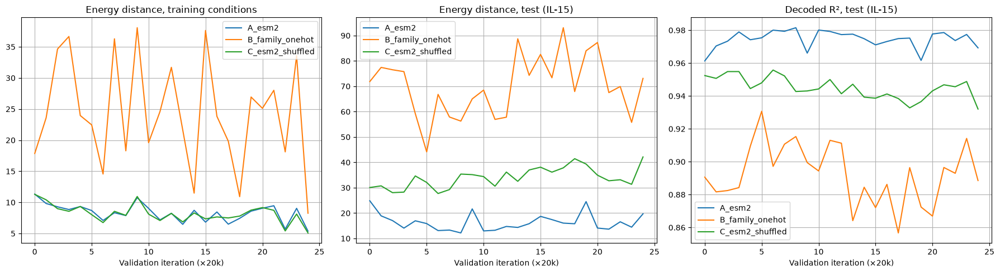

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for arm, logs in training_logs.items():
    if not logs:
        continue
    axes[0].plot(logs.get("train_e_distance_mean", []), label=arm)
    axes[1].plot(logs.get("test_e_distance_mean", []), label=arm)
    axes[2].plot(logs.get("pca_decoded_test_r_squared_mean", []), label=arm)
for ax, t in zip(axes, ["Energy distance, training conditions", "Energy distance, test (IL-15)", "Decoded R², test (IL-15)"]):
    ax.set_title(t); ax.set_xlabel("Validation iteration (×20k)"); ax.legend(); ax.grid(True)
plt.tight_layout()
plt.show()

## Evaluation (06's procedure, all arms plus the control-mean baseline)

In [11]:
MIN_CELLS = 20


def _dense(X):
    return X.toarray() if sp.issparse(X) else np.asarray(X)


def evaluate(candidates_by_cond, adata_true, group_key=None):
    rows = []
    for cond in adata_true.obs["condition"].unique():
        donor = cond.split("_")[0]
        true_c = adata_true[adata_true.obs["condition"] == cond]
        candidates = candidates_by_cond(cond, donor)
        groups = [None] if group_key is None else sorted(true_c.obs[group_key].astype(str).unique())
        for g in groups:
            t = true_c if g is None else true_c[true_c.obs[group_key].astype(str) == g]
            subsets = {m: (a if g is None else a[a.obs[group_key].astype(str) == g]) for m, a in candidates.items()}
            if min([t.n_obs] + [s.n_obs for s in subsets.values()]) < MIN_CELLS:
                continue
            t_X, t_pca = _dense(t.X), np.asarray(t.obsm["X_pca"])
            for model, s in subsets.items():
                rows.append({
                    "condition": cond, "donor": donor, "cell_type": "all" if g is None else g, "model": model,
                    "n_true": t.n_obs, "n_pred": s.n_obs,
                    "r_squared": float(compute_r_squared(t_X, _dense(s.X))),
                    "e_distance": float(compute_e_distance(t_pca, np.asarray(s.obsm["X_pca"]))),
                })
    return pd.DataFrame(rows)

As in 06, distributional metrics use a 30-PC space fitted on a 100k-cell subsample of the **entire** dataset
(train + test), onto which true, generated and control cells are projected. 06 subsampled `adata` before the split.
Here `adata` was freed to save memory, so it is rebuilt from the same file with the same `random_state=0`, which gives
the identical subsample.

Groups (donor × cell type) are kept only if **every** model has ≥ `MIN_CELLS` cells in them, so all four columns
of a row are computed on the same cells. With more arms, a few rows that 06 kept may therefore drop out.

In [12]:
adata_full = ad.read_h5ad(DATA_PATH)
adata_full.obs["condition"] = adata_full.obs.apply(lambda x: x["donor"] + "_" + x["cytokine"], axis=1)
adata_full.obs["is_control"] = adata_full.obs.apply(lambda x: True if x["cytokine"]=="PBS" else False, axis=1)
sc.pp.normalize_total(adata_full, target_sum=1e4)
sc.pp.log1p(adata_full)
adata_ref = sc.pp.subsample(adata_full, n_obs=100_000, copy=True)
del adata_full
gc.collect()
cfpp.centered_pca(adata_ref, n_comps=30)

adata_true = adata_test_for_validation[~adata_test_for_validation.obs["is_control"].to_numpy()].copy()
adata_ctrl_baseline = adata_ctrl_for_prediction.copy()
cfpp.project_pca(query_adata=adata_true, ref_adata=adata_ref)
cfpp.project_pca(query_adata=adata_ctrl_baseline, ref_adata=adata_ref)
for arm in ARMS:
    cfpp.project_pca(query_adata=preds_by_arm[arm], ref_adata=adata_ref)


def candidates_by_cond(cond, donor):
    c = {arm: p[p.obs["condition"] == cond] for arm, p in preds_by_arm.items()}
    c["control_mean"] = adata_ctrl_baseline[adata_ctrl_baseline.obs["donor"] == donor]
    return c


MODELS = list(ARMS) + ["control_mean"]
df_donor = evaluate(candidates_by_cond, adata_true)
df_celltype = evaluate(candidates_by_cond, adata_true, "cell_type")
df_all = pd.concat([df_donor, df_celltype], ignore_index=True)
df_all.to_csv(os.path.join(MODEL_DIR, f"{MODEL_PREFIX}_metrics.csv"), index=False)

### Reproducibility check: arm A vs 06

In [13]:
ref06 = pd.read_csv(BASELINE_METRICS)
chk = df_donor[df_donor["model"].isin(["A_esm2", "control_mean"])].merge(
    ref06.replace({"model": {"CellFlow": "A_esm2"}}), on=["donor", "model"], suffixes=("_08", "_06"))
chk[["donor", "model", "r_squared_08", "r_squared_06", "e_distance_08", "e_distance_06"]].round(4)

,donor,model,r_squared_08,r_squared_06,e_distance_08,e_distance_06
0,Donor12,A_esm2,0.9469,0.9469,22.1994,22.2032
1,Donor12,control_mean,0.7092,0.7092,166.5204,166.5204
2,Donor1,A_esm2,0.9809,0.9809,7.2622,7.2813
3,Donor1,control_mean,0.9165,0.9165,55.5059,55.5059
4,Donor2,A_esm2,0.9461,0.9462,20.1267,20.0948
5,Donor2,control_mean,0.8380,0.8380,82.6986,82.6986


## Results: one table

R² (higher is better) and energy distance (lower is better) on held-out IL-15, per donor (`cell_type = all`) and
per donor × cell type, for the three arms and the control-mean baseline. The last block is the mean over donors.

In [14]:
table = df_all.pivot_table(index=["donor", "cell_type"], columns="model", values=["r_squared", "e_distance"])
table = table.reindex(columns=pd.MultiIndex.from_product([["r_squared", "e_distance"], MODELS]))
mean_rows = df_all.groupby(["cell_type", "model"])[["r_squared", "e_distance"]].mean().unstack("model")
mean_rows = mean_rows.reindex(columns=table.columns)
mean_rows.index = pd.MultiIndex.from_product([["mean over donors"], mean_rows.index])
table = pd.concat([table, mean_rows])
table.to_csv(os.path.join(MODEL_DIR, f"{MODEL_PREFIX}_table.csv"))
pd.set_option("display.max_rows", 200)
table.round(4)

r_squared                  \
                                          A_esm2 B_family_onehot   
                 cell_type                                         
Donor1           B Intermediate/Memory    0.9207          0.9048   
                 B Naive                  0.9188          0.9131   
                 CD14 Mono                0.9733          0.9311   
                 CD16 Mono                0.9553          0.9283   
                 CD4 Memory               0.9731          0.9023   
                 CD4 Naive                0.9745          0.9389   
                 CD8 Memory               0.9011          0.8443   
                 MAIT                     0.9076          0.8667   
                 NK                       0.8955          0.8616   
                 NK CD56bright            0.8682          0.8000   
                 Treg                     0.9210          0.8763   
                 all                      0.9809          0.9384   
                 cDC                      0.9217          0.8983   
Donor12          B Intermediate/Memory    0.9265          0.8901   
                 B Naive                  0.9287          0.8812   
                 CD14 Mono                0.9642          0.8882   
                 CD16 Mono                0.9025          0.8414   
                 CD4 Memory               0.9270          0.7374   
                 CD4 Naive                0.9438          0.7940   
                 CD8 Memory               0.8085          0.6569   
                 CD8 Naive                0.8774          0.7241   
                 MAIT                     0.8336          0.7230   
                 NK                       0.8305          0.7163   
                 Treg                     0.8092          0.6907   
                 all                      0.9469          0.8032   
Donor2           B Intermediate/Memory    0.9570          0.9537   
                 B Naive                  0.9605          0.9657   
                 CD14 Mono                0.9535          0.9451   
                 CD16 Mono                0.9164          0.9057   
                 CD4 Memory               0.9155          0.8232   
                 CD4 Naive                0.9600          0.9058   
                 CD8 Memory               0.7952          0.7092   
                 CD8 Naive                0.8682          0.7677   
                 MAIT                     0.7719          0.7050   
                 NK                       0.8664          0.8225   
                 NK CD56bright            0.8475          0.7990   
                 Treg                     0.8939          0.8564   
                 all                      0.9461          0.8937   
mean over donors B Intermediate/Memory    0.9348          0.9162   
                 B Naive                  0.9360          0.9200   
                 CD14 Mono                0.9637          0.9215   
                 CD16 Mono                0.9247          0.8918   
                 CD4 Memory               0.9385          0.8210   
                 CD4 Naive                0.9595          0.8796   
                 CD8 Memory               0.8349          0.7368   
                 CD8 Naive                0.8728          0.7459   
                 MAIT                     0.8377          0.7649   
                 NK                       0.8641          0.8002   
                 NK CD56bright            0.8579          0.7995   
                 Treg                     0.8747          0.8078   
                 all                      0.9580          0.8784   
                 cDC                      0.9217          0.8983   

                                                                     \
                                       C_esm2_shuffled control_mean   
                 cell_type                                            
Donor1           B Intermediate/Memory          0.9150       0.8972   
              

### Summary: donor-level (`cell_type = all`)

In [15]:
summary = df_donor.pivot_table(index="donor", columns="model", values=["r_squared", "e_distance"]) \
    .reindex(columns=pd.MultiIndex.from_product([["r_squared", "e_distance"], MODELS]))
summary.loc["mean"] = summary.mean()
summary.round(4)

r_squared                                              e_distance  \
           A_esm2 B_family_onehot C_esm2_shuffled control_mean     A_esm2   
donor                                                                       
Donor1     0.9809          0.9384          0.9778       0.9165     7.2622   
Donor12    0.9469          0.8032          0.9405       0.7092    22.1994   
Donor2     0.9461          0.8937          0.8460       0.8380    20.1267   
mean       0.9580          0.8784          0.9214       0.8212    16.5294   

                                                      
        B_family_onehot C_esm2_shuffled control_mean  
donor                                                 
Donor1          42.1300         10.6137      55.5059  
Donor12        109.4078         25.8289     166.5204  
Donor2          48.8621         77.3700      82.6986  
mean            66.8000         37.9376     101.5749

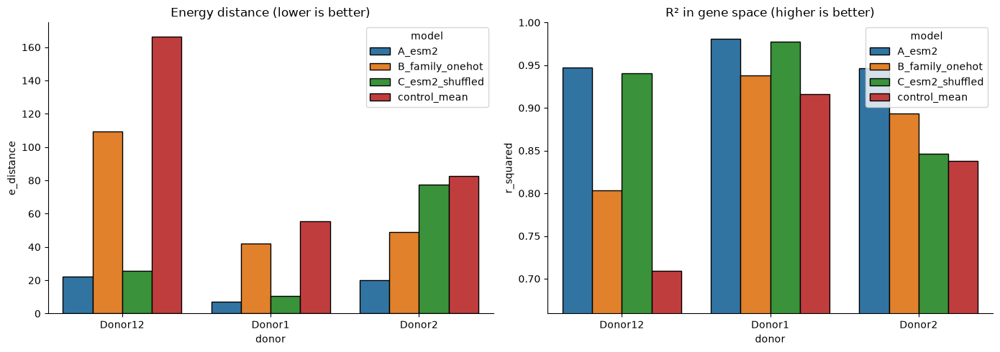

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=df_donor, x="donor", y="e_distance", hue="model", hue_order=MODELS, edgecolor="black", ax=axes[0])
axes[0].set_title("Energy distance (lower is better)")
sns.barplot(data=df_donor, x="donor", y="r_squared", hue="model", hue_order=MODELS, edgecolor="black", ax=axes[1])
axes[1].set_title("R² in gene space (higher is better)")
axes[1].set_ylim(df_donor["r_squared"].min() - 0.05, 1)
sns.despine()
plt.tight_layout()
plt.show()

### Where each arm sits between A and the control-mean baseline

For each donor and metric: **gap closed** = (control − arm) / (control − A) for e-distance, and the mirror for R².
1 means as good as ESM2 (A), 0 means no better than doing nothing (control-mean). Cell-type rows are summarised as the
median over cell types.

In [17]:
def gap_closed(df):
    w = df.pivot_table(index=["donor", "cell_type"], columns="model", values=["r_squared", "e_distance"])
    out = {}
    for arm in ["B_family_onehot", "C_esm2_shuffled"]:
        out[(arm, "e_distance")] = (w[("e_distance", "control_mean")] - w[("e_distance", arm)]) / \
                                   (w[("e_distance", "control_mean")] - w[("e_distance", "A_esm2")])
        out[(arm, "r_squared")] = (w[("r_squared", arm)] - w[("r_squared", "control_mean")]) / \
                                  (w[("r_squared", "A_esm2")] - w[("r_squared", "control_mean")])
    return pd.DataFrame(out)


gc_ = gap_closed(df_all)
gap = pd.concat({
    "donor level": gc_.xs("all", level="cell_type"),
    "cell types (median)": gc_.drop(index="all", level="cell_type").groupby(level="donor").median(),
})
gap.round(2)

B_family_onehot           C_esm2_shuffled  \
                                 e_distance r_squared      e_distance   
                    donor                                               
donor level         Donor1             0.28      0.34            0.93   
                    Donor12            0.40      0.40            0.97   
                    Donor2             0.54      0.52            0.09   
cell types (median) Donor1             0.35      0.40            0.92   
                    Donor12            0.40      0.41            0.99   
                    Donor2             0.47      0.52            0.07   

                                       
                            r_squared  
                    donor              
donor level         Donor1       0.95  
                    Donor12      0.97  
                    Donor2       0.07  
cell types (median) Donor1       0.91  
                    Donor12      0.98  
                    Donor2       0.09

## How to read the result

The three readings requested, with one caveat on each that this particular split creates:

* **If B ≈ A, coarse receptor-family information carries most of the signal.** In B, IL-15 is literally the same
  input as the other seven γ-chain cytokines, so B ≈ A would mean IL-15's effect in the held-out donors is predicted as
  well by "a generic γ-chain response" as by IL-15's own sequence embedding.
* **If C ≈ A, the model is ignoring the ligand representation.** Caveat: in this split IL-15 **is** in training
  (Donor8), so its shuffled vector is still a unique, consistent label that the model can learn from Donor8 and
  reuse for the other donors. C ≈ A therefore shows that the ESM2 *content* is not needed for this donor-transfer
  task. It does not show that the representation is ignored: a unique ID works as well as a meaningful vector. Testing
  "ignored entirely" would need an arm with one constant vector for every cytokine. Testing whether ESM2 content
  matters would need an unseen-cytokine split (IL-15 absent for all donors).
* **If C ≈ control-mean, ESM2 conditioning is doing real work.**

## Conclusion

_(filled in after the run)_